In [13]:
import warnings
warnings.filterwarnings("ignore")

In [14]:
import tensorflow as tf; 
print("Tensorflow Version:",tf.__version__)
print(tf.config.list_physical_devices('GPU'))

Tensorflow Version: 2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [15]:
# Cell 1: Imports, reproducibility, and publication-grade plotting

from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import tensorflow as tf

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# -----------------------------
# Publication-grade plotting style
# -----------------------------
mpl.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,

    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.8,
    "lines.markersize": 5,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": False,
    "legend.frameon": False,
    "image.cmap": "viridis",
})

# Colorblind-friendly palette
CB_COLORS = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # green
    "#CC79A7",  # purple
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#F0E442",  # yellow
    "#000000",  # black
]

print("TensorFlow version:", tf.__version__)
print("Setup complete with publication-grade plotting.")

TensorFlow version: 2.16.1
Setup complete with publication-grade plotting.


In [16]:
# Cell 1B: Save figures in manuscript-friendly formats

def save_figure(fig, out_dir, stem_name):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    png_path = out_dir / f"{stem_name}.png"
    pdf_path = out_dir / f"{stem_name}.pdf"

    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")

    print("Saved:")
    print(" -", png_path)
    print(" -", pdf_path)

In [17]:
# Cell 2: Project paths

PROJECT_ROOT = Path.cwd().resolve().parents[0] if "notebooks" in str(Path.cwd()) else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"

CHBMIT_DIR = RAW_DIR / "chbmit"
TURKISH_DIR = RAW_DIR / "turkish"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
LOG_DIR = OUTPUT_DIR / "logs"
MODEL_DIR = OUTPUT_DIR / "models"

for d in [FIG_DIR, TABLE_DIR, LOG_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CHBMIT_DIR exists:", CHBMIT_DIR.exists(), CHBMIT_DIR)
print("TURKISH_DIR exists:", TURKISH_DIR.exists(), TURKISH_DIR)

PROJECT_ROOT: /home/harman/projects/Sachin_Epilepsy_Revised
CHBMIT_DIR exists: True /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/chbmit
TURKISH_DIR exists: True /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/turkish


In [18]:
# Cell 3: TensorFlow device check

gpus = tf.config.list_physical_devices("GPU")
cpus = tf.config.list_physical_devices("CPU")

print("CPUs:", cpus)
print("GPUs:", gpus)

if gpus:
    print("Using GPU with TensorFlow.")
else:
    print("GPU not detected. Running on CPU.")

CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using GPU with TensorFlow.


In [19]:
# Cell 4: Inspect dataset file structure

def list_files_recursive(root: Path, max_items: int = 30):
    if not root.exists():
        print(f"Path does not exist: {root}")
        return []
    
    files = [p for p in root.rglob("*") if p.is_file()]
    files = sorted(files)
    
    print(f"\nFolder: {root}")
    print(f"Total files found: {len(files)}")
    print("Sample files:")
    for p in files[:max_items]:
        print(" -", p.relative_to(root))
    return files

chbmit_files = list_files_recursive(CHBMIT_DIR, max_items=20)
turkish_files = list_files_recursive(TURKISH_DIR, max_items=20)


Folder: /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/chbmit
Total files found: 2139
Sample files:
 - ANNOTATORS
 - ANNOTATORS:Zone.Identifier
 - RECORDS
 - RECORDS-WITH-SEIZURES
 - RECORDS-WITH-SEIZURES:Zone.Identifier
 - RECORDS-WITH-SEIZURES:Zone.Identifier:Zone.Identifier
 - RECORDS:Zone.Identifier
 - RECORDS:Zone.Identifier:Zone.Identifier
 - SHA256SUMS.txt
 - SHA256SUMS.txt:Zone.Identifier
 - SHA256SUMS.txt:Zone.Identifier:Zone.Identifier
 - SUBJECT-INFO
 - SUBJECT-INFO:Zone.Identifier
 - SUBJECT-INFO:Zone.Identifier:Zone.Identifier
 - chb01/chb01-summary.txt
 - chb01/chb01-summary.txt:Zone.Identifier
 - chb01/chb01_01.edf
 - chb01/chb01_01.edf:Zone.Identifier
 - chb01/chb01_02.edf
 - chb01/chb01_02.edf:Zone.Identifier

Folder: /home/harman/projects/Sachin_Epilepsy_Revised/data/raw/turkish
Total files found: 242
Sample files:
 - epilepsy/1_epilepsy (1).mat
 - epilepsy/1_epilepsy (1).mat:Zone.Identifier
 - epilepsy/1_epilepsy (10).mat
 - epilepsy/1_epilepsy (10).mat:Zone

In [20]:
# Cell 5: Build dataset inventory table

def summarize_extensions(file_list):
    ext_counts = {}
    for f in file_list:
        ext = f.suffix.lower() if f.suffix else "[no_ext]"
        ext_counts[ext] = ext_counts.get(ext, 0) + 1
    return ext_counts

chbmit_ext = summarize_extensions(chbmit_files)
turkish_ext = summarize_extensions(turkish_files)

inventory_rows = []
for dataset_name, ext_dict, total in [
    ("CHB-MIT", chbmit_ext, len(chbmit_files)),
    ("Turkish", turkish_ext, len(turkish_files)),
]:
    for ext, count in sorted(ext_dict.items(), key=lambda x: x[0]):
        inventory_rows.append({
            "dataset": dataset_name,
            "file_extension": ext,
            "count": count,
            "total_files": total
        })

inventory_df = pd.DataFrame(inventory_rows)
inventory_df

,dataset,file_extension,count,total_files
0,CHB-MIT,.edf,686,2139
1,CHB-MIT,.identifier,1282,2139
2,CHB-MIT,.pdf,1,2139
3,CHB-MIT,.seizures,141,2139
4,CHB-MIT,.txt,25,2139
5,CHB-MIT,[no_ext],4,2139
6,Turkish,.identifier,121,242
7,Turkish,.mat,121,242


In [21]:
inventory_df.to_csv(TABLE_DIR / "dataset_inventory.csv", index=False)
print("Saved:", TABLE_DIR / "dataset_inventory.csv")

Saved: /home/harman/projects/Sachin_Epilepsy_Revised/outputs/tables/dataset_inventory.csv


Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig01_dataset_filetype_distribution.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig01_dataset_filetype_distribution.pdf


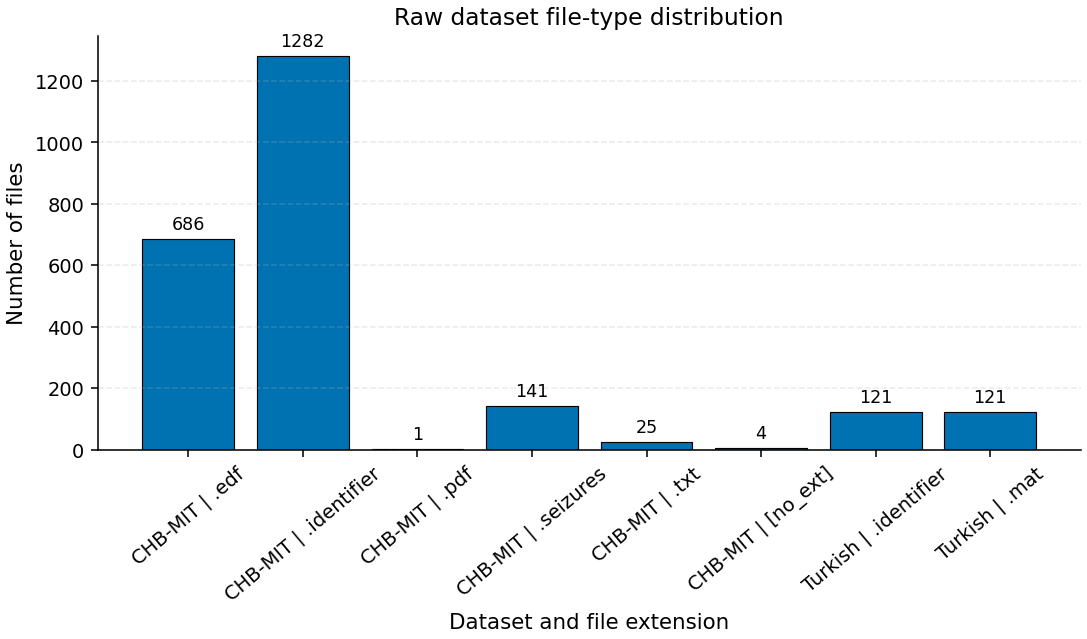

In [22]:
# Cell 6: Journal-style raw file-type distribution

fig, ax = plt.subplots(figsize=(8, 4.8))

plot_df = inventory_df.copy()
plot_df["label"] = plot_df["dataset"] + " | " + plot_df["file_extension"]

bars = ax.bar(
    plot_df["label"],
    plot_df["count"],
    color=CB_COLORS[0],
    edgecolor="black",
    linewidth=0.6
)

ax.set_ylabel("Number of files")
ax.set_xlabel("Dataset and file extension")
ax.set_title("Raw dataset file-type distribution")
ax.tick_params(axis="x", rotation=40)

ax.grid(axis="y", linestyle="--", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
save_figure(fig, FIG_DIR, "fig01_dataset_filetype_distribution")
plt.show()

Saved:
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig02_raw_file_count_by_dataset.png
 - /home/harman/projects/Sachin_Epilepsy_Revised/outputs/figures/fig02_raw_file_count_by_dataset.pdf


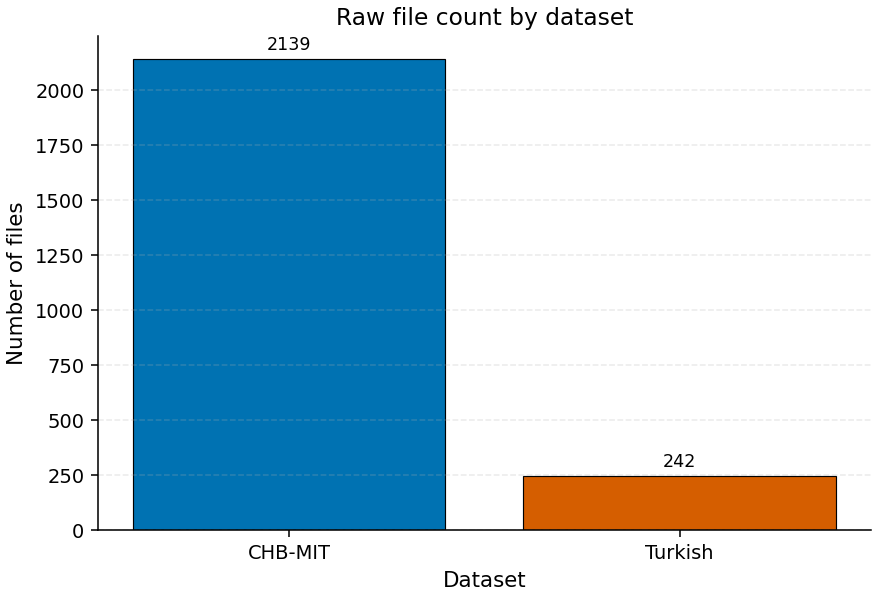

In [23]:
# Cell 7: Total file count by dataset

dataset_counts = pd.DataFrame({
    "dataset": ["CHB-MIT", "Turkish"],
    "file_count": [len(chbmit_files), len(turkish_files)]
})

fig, ax = plt.subplots(figsize=(6.5, 4.5))

bars = ax.bar(
    dataset_counts["dataset"],
    dataset_counts["file_count"],
    color=[CB_COLORS[0], CB_COLORS[1]],
    edgecolor="black",
    linewidth=0.6
)

ax.set_ylabel("Number of files")
ax.set_xlabel("Dataset")
ax.set_title("Raw file count by dataset")
ax.grid(axis="y", linestyle="--", alpha=0.25)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
save_figure(fig, FIG_DIR, "fig02_raw_file_count_by_dataset")
plt.show()